# One Memory, Many Agents: Giving a Team of MemAgents a Shared Memory

Ask three agents at the same company the same question and you'll get three
answers. One of them will be confident.

It isn't a model problem. The merchandising agent decided yesterday that the
sale starts on the 3rd. The copywriting agent was never told, so it wrote
"this weekend". The support agent has never heard of a sale at all — and it
is the one the customer is talking to.

Each agent is doing its job well. They just don't share a memory, so the
company knows something that two-thirds of the company can't recall.

**This notebook is about telling a team something once.**

We take one small business with three agents, measure what they know when
each has its own memory, then give them a single shared one and measure
again. Along the way we look at what "shared" is made of, how a change
reaches every agent, what should *not* be shared, how a coordinator hands
one job to the whole team, and how to tell who wrote what.

It is the first of three parts. Notebook 2 gives the same memory to coding
agent harnesses (Codex, Claude Code, pi). Part 3 connects personal
assistants to it. The memory doesn't change. Only who is reading it does.

## Key takeaways

- ***Agents don't share a memory by being on the same team.*** *They share one by reading and writing the same memory ID in the same store.*
- ***A memory ID is a boundary, not a label.*** *Everything written under it reaches every agent that runs in it — and nothing that doesn't.*
- ***Shared memory is not messaging.*** *Mara never tells Cole anything. She writes a record; Cole reads it when he needs it.*
- ***One edit, every agent.*** *Change a decision once and the next answer from any agent carries it. No re-prompting, no redeploy.*
- ***Few writers, many readers.*** *Every agent that can write a shared record can also write it wrong. Give the pen to the role that owns the decision.*
- ***Share the plan, not the customer.*** *What everyone must know goes in the shared memory. What one agent must protect stays in its own.*
- ***A shared memory needs an audit trail.*** *When four agents can write, "who told the memory that?" stops being a rhetorical question.*

## How this notebook is organised

Eleven short parts. Each opens by saying what you'll learn and what you'll
have at the end of it.

| Part | What happens | What you have at the end |
|---|---|---|
| **1 · The use case** | A plant shop, a sale, and three agents who disagree | The problem, and five terms for the fix |
| **2 · Setup and the shop** | A memory store, a handbook, three agents | A team you can talk to |
| **3 · Three agents, three memories** | Each agent runs in a memory of its own | A measured picture of what goes wrong |
| **4 · One memory ID** | The same agents, run in one shared memory | The same questions, answered correctly |
| **5 · What is actually shared** | We open the store and count what's in it | The four layers, with real rows |
| **6 · A decision changes** | The sale is extended; nobody is told. Then a reader tries to rewrite it | One edit that reaches every agent, and a record only its owner can change |
| **7 · What stays private** | A customer's details, in a memory of their own | A boundary you can test |
| **8 · One task, the whole team** | A coordinator splits a job across the three | A launch pack, and the board that produced it |
| **9 · Who wrote that?** | The store's change history, per agent | An audit trail for a shared memory |
| **10 · See it in the UI** | The same store in the MemoRizz console | Agents, memory and traces, on screen |
| **11 · Trade-offs** | When sharing is the wrong call | Practical guidance, and an FAQ |

Running it end to end makes about twenty small model calls and takes two to
three minutes on the default model.

# Part 1 · The use case

This part is the *why*. You'll meet the shop, see how three capable agents
end up telling three stories, and get the five terms the rest of the
notebook is built from. No code runs here.

## ⭐ The use case: a spring sale at a plant shop

**Fern & Ember** is an independent online plant shop. It is small enough
that three agents do the work of three departments:

1. **Mara**, the merchandiser, decides offers: dates, discounts, exclusions.
2. **Cole**, the copywriter, writes the emails and product copy.
3. **Sam**, in support, answers customers.

On Monday Mara is given the decision: the **Spring Sale runs 3 to 9 March
2027, with 20% off houseplants and 10% off pots; gift cards are excluded**.

On Tuesday Cole is asked for the announcement email, and a customer asks
Sam when the sale starts.

Nothing about this is exotic. It is every team that has ever had a decision
made in one room and needed in two others. You could swap the plant shop
for a clinic, a law firm or a product team and keep every line of code.

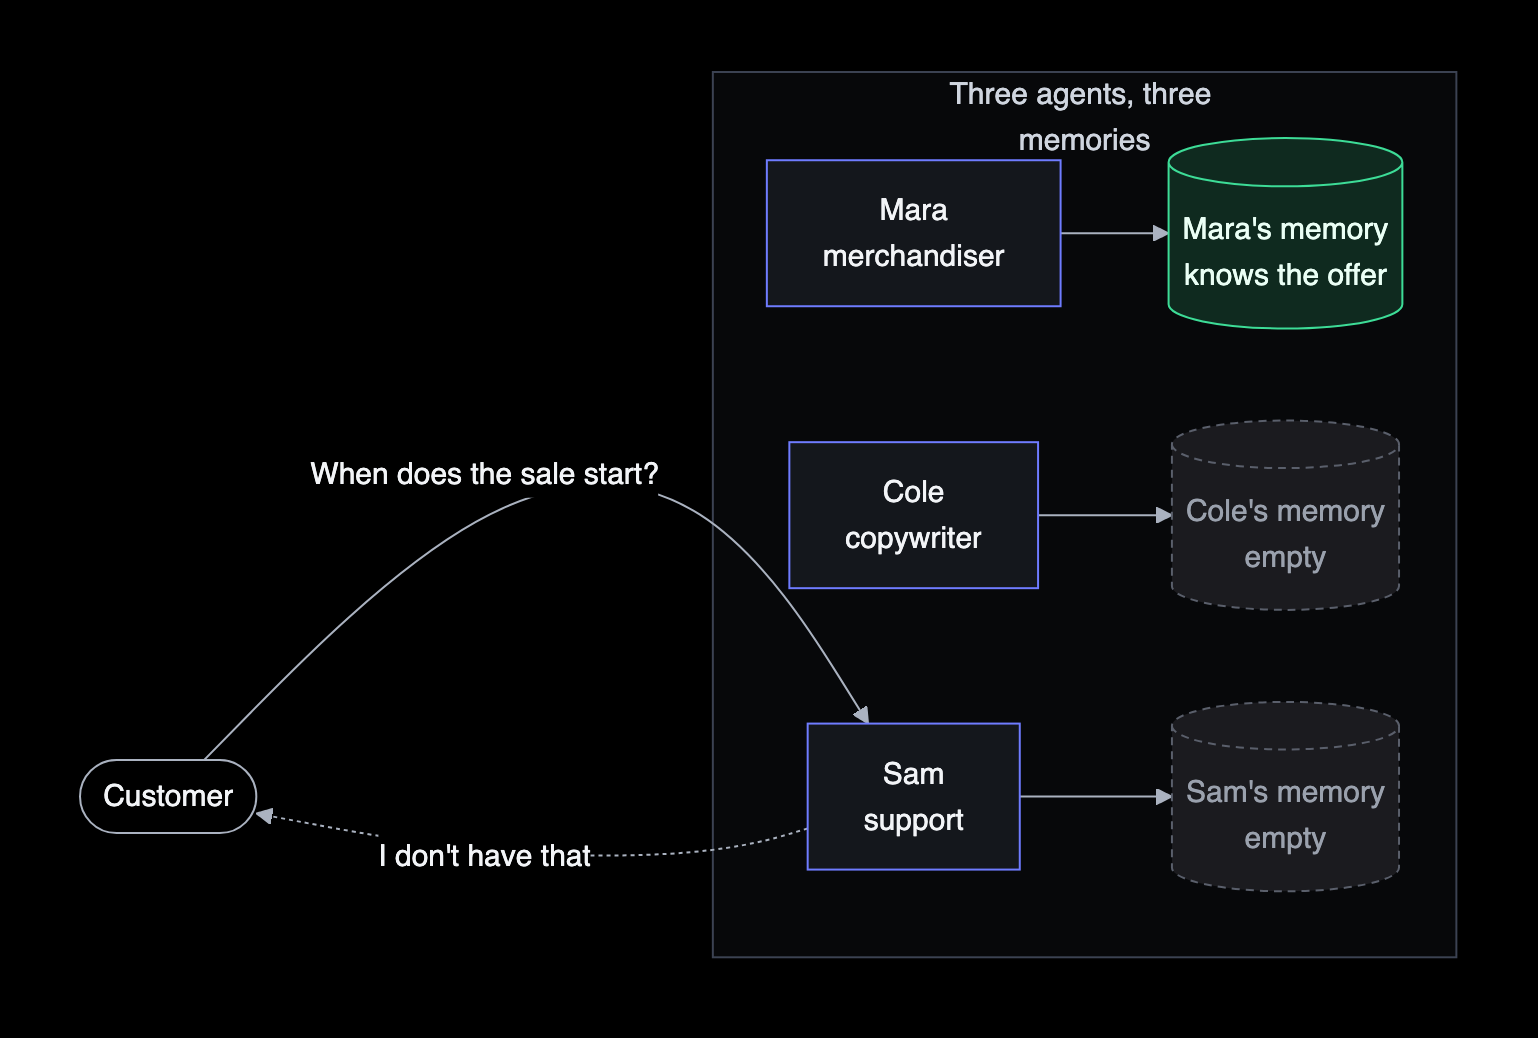

**How to read it.** Mara's memory holds the offer. Cole's and Sam's are
empty of it, so when the customer asks, the agent they reach has nothing to
retrieve. The gap isn't in any agent. It's between them.

## The fixes people reach for first

There are three familiar ways to close that gap, and each one works right
up until it doesn't.

- **Put it in every prompt.** Paste the offer into all three system
  prompts. Now a change means editing three prompts and redeploying three
  agents, and the day you forget one, you're back to three stories.
- **Have the agents message each other.** Mara tells Cole, Cole tells Sam.
  It works for two agents. At five it is a group chat, and "who did I
  forget to tell?" becomes the bug. Coordination becomes the tax.
- **Give every agent the whole conversation.** Stuff Mara's transcript into
  Cole's context. It is correct, expensive, and gets slower every day the
  shop is open.

All three treat knowledge as something you *send*. The alternative is to
treat it as something you *keep* — in one place, where any agent that needs
it can look.

> A decision that lives in a prompt has to be delivered. A decision that
> lives in memory only has to be found.

## ⭐ Five terms, defined once

Each is defined here and used the same way throughout.

- **A memory provider is the store an agent reads and writes its memory
  through.** Here it is a folder of JSON files; in production it is usually
  a database. Agents can only share what lives in the same provider.
- **A memory ID is the name of one memory inside that store.** Every record
  an agent writes during a turn is filed under the memory ID that turn ran
  in, and retrieval only looks there.
- **A shared memory is a memory ID that more than one agent runs in.**
  That's the whole mechanism. No bus, no broker, no subscriptions.
- **A private memory is a memory ID only one agent runs in.** Same store,
  same code, a different name — and a real boundary.
- **A coordination board is a shared session a coordinator opens for one
  task**, where it posts the plan and each agent posts what it did. It is
  the team's working memory for a job, kept after the job ends.

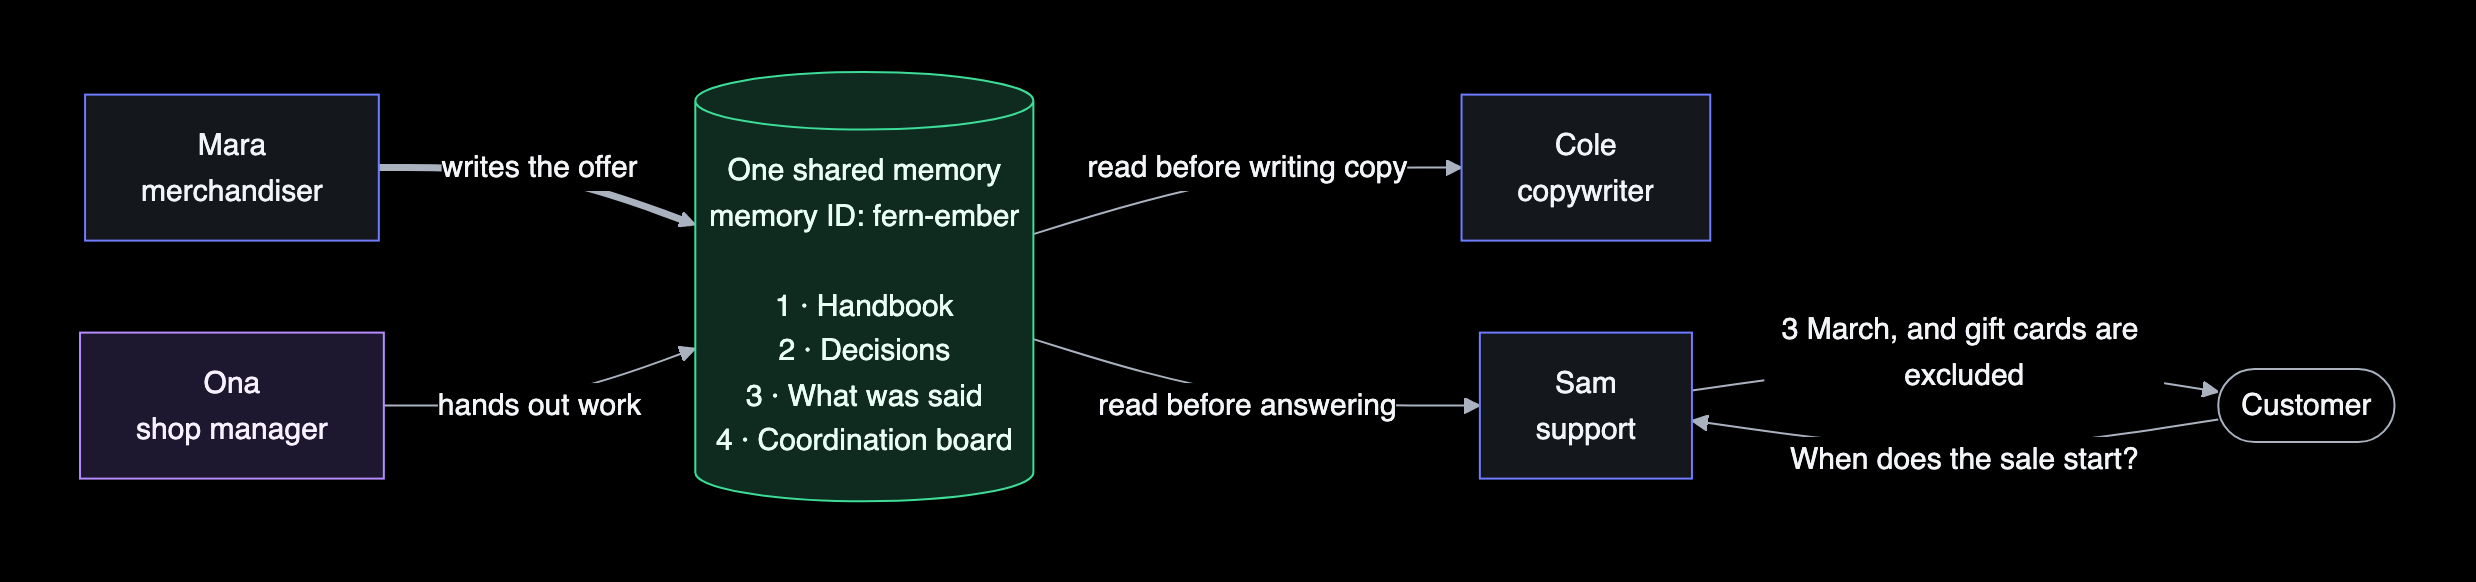

**How to read it.** Mara writes the offer once, into the shared memory.
Cole and Sam read it at the moment they need it — Cole before he writes,
Sam before he answers. Ona, the shop manager, appears in Part 8, where she
uses the same memory to hand out work.

The cylinder has four layers, and we'll put real rows in each:

| Layer | MemoRizz memory type | What it holds here | Who writes it |
|---|---|---|---|
| **1 · Handbook** | Knowledge base | Brand voice and standing rules | You, once |
| **2 · Decisions** | Entity memory | The Spring Sale: dates, discounts, exclusions | Mara |
| **3 · What was said** | Conversation memory | Every turn any agent had in this memory | All of them |
| **4 · Coordination board** | Shared memory session | The plan and results of one delegated task | Ona and her team |

# Part 2 · Setup and the shop

This part builds the stage: a memory store, the shop's handbook, and three
agents. By the end there is a team you can talk to — and it does not yet
share anything it learns.

## 0 · Setup

Three things happen in the next cells, and each is deliberate.

1. **MemoRizz is installed only if it is missing**, with the local UI
   (`ui`) and the file store's vector index (`filesystem`).
2. **The store is a folder beside this notebook**, `fern_ember_store`, so
   you can open it in an editor and, in Part 10, in the MemoRizz console.
   Notebook 2 reads the same folder.
3. **Every run starts from an empty shop.** Set `FRESH = False` to keep
   what earlier runs wrote.

The notebook needs **MemoRizz 0.17.27 or later**: a reader's
`policy={"writes": False}`, used below, arrived in that release. Upgrade an
older install with `pip install -U "memorizz[ui,filesystem]"`.

In [1]:
import importlib.util
import json
import logging
import os
import re
import shutil
import textwrap
from collections import Counter
from pathlib import Path

# MemoRizz from PyPI, with the local UI and the file store. Skipped when it is already installed.
if importlib.util.find_spec("memorizz") is None:
    %pip install --quiet "memorizz[ui,filesystem]>=0.17.27"

**The model key.** The agents run on an OpenAI model, so the key has to be
in the environment, or in a `.env` file in this folder or above it.

In [2]:
if not os.getenv("OPENAI_API_KEY"):
    from dotenv import dotenv_values, find_dotenv

    os.environ["OPENAI_API_KEY"] = (
        dotenv_values(find_dotenv(usecwd=True)).get("OPENAI_API_KEY") or ""
    )
assert os.environ["OPENAI_API_KEY"], "Set OPENAI_API_KEY before running this notebook."

**Where memory lives.** `STORE` is the folder every agent will read and
write. `MEMORIZZ_HOME` is pointed at a folder beside it, so this notebook
never touches your own MemoRizz settings.

In [3]:
FRESH = True  # start every run from an empty shop
STORE = Path(os.getenv("MEMORIZZ_NB_STORE") or Path.cwd() / "fern_ember_store").resolve()
os.environ["MEMORIZZ_HOME"] = str(STORE.parent / "fern_ember_home")

if FRESH and STORE.exists():
    shutil.rmtree(STORE)
logging.disable(logging.WARNING)  # keep the lesson's output readable

**Next: the provider, the model, and the name of the shared memory.** These
names are used by every later cell, so they're worth a glance first.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `FileSystemProvider` | MemoRizz API | The *memory provider*: the object every agent reads and writes memory through | **One provider for all agents.** Sharing starts here: two agents on two stores share nothing |
| `FileSystemConfig(root_path=...)` | MemoRizz API | Points the provider at a folder; `embedding_provider` and `embedding_config` say how text becomes vectors for search | A small OpenAI embedding model at 256 dimensions: cheap, and plenty for a shop this size |
| `LLM` | Notebook value | The chat model every agent uses | One cheap model for all four agents, so differences in their answers come from memory, not from the model |
| `TEAM` | Notebook value | The memory ID the team shares: `"fern-ember"` | The single most important string in the notebook |

In [4]:
import memorizz
from memorizz import FileSystemConfig, FileSystemProvider

EMBEDDING = {"model": "text-embedding-3-small", "dimensions": 256}
provider = FileSystemProvider(
    FileSystemConfig(root_path=STORE, embedding_provider="openai", embedding_config=EMBEDDING)
)

LLM = {"provider": "openai", "model": os.getenv("MEMORIZZ_NB_CHAT_MODEL", "gpt-6-luna")}
TEAM = "fern-ember"  # the memory ID the whole team shares
print("memorizz", memorizz.__version__, "| store:", STORE.name, "| model:", LLM["model"])

memorizz 0.17.27 | store: fern_ember_store | model: gpt-6-luna


**Turn on the audit trail before anything is written.** `MemoryHistory`
records every change to the store with the agent that made it. We switch it
on now and don't look at it until Part 9 — an audit trail you turn on after
the incident is a diary.

In [5]:
from memorizz import MemoryHistory

history = MemoryHistory(provider, record_changes=True)

**Two helpers, so the lesson's cells stay short.** Neither teaches anything
about memory.

| Name | What it does |
|---|---|
| `say(who, text)` | Prints an agent's answer, wrapped, with its name in front |
| `knows(text, last_day)` | Returns which facts of the offer an answer carries: the dates, the 20% and the 10%. It is a plain string check, not a model |

In [6]:
def say(who, text):
    print(textwrap.fill(f"{who}: {text}", width=100, subsequent_indent="    "), end="\n\n")


def knows(text, last_day="9"):
    """Which facts of the offer an answer carries."""
    words = re.findall(r"[a-z0-9]+", text.lower())
    dates = "3" in words and last_day in words and "march" in words
    return [
        fact
        for fact, present in (("dates", dates), ("20%", "20%" in text), ("10%", "10%" in text))
        if present
    ]

## ⭐ Layer 1: the handbook

Some of what a team knows never changes from week to week: how the shop
sounds, what it never does. That is a **knowledge base** — text you ingest
once and attach to every agent that should follow it.

| Name | Kind | What it does |
|---|---|---|
| `KnowledgeBase(provider)` | MemoRizz API | Reads and writes knowledge-base records in the store |
| `.ingest_knowledge(text, namespace, chunking_strategy=...)` | MemoRizz API | Splits the text into chunks, embeds each, stores them, and returns one **knowledge base ID** |

`"paragraph"` chunking keeps each rule as its own record, so a question
about delivery retrieves the delivery rule and not the whole page.

In [7]:
HANDBOOK = """
Fern & Ember brand voice: warm, plain and never pushy. No exclamation marks. Write like a
friend who knows plants.

Standing rule: gift cards are never discounted, in any sale.

Standing rule: delivery is free on orders over 35 pounds. Under that, delivery is 3.95 pounds.

Standing rule: plants that arrive damaged are replaced free within 14 days, with a photo.
"""

In [8]:
from memorizz import KnowledgeBase

handbook_id = KnowledgeBase(provider).ingest_knowledge(
    HANDBOOK, "fern-ember-handbook", chunking_strategy="paragraph"
)
print("handbook:", handbook_id)

handbook: c9a09c38-3c02-4b1e-8c59-799d3864a628


## ⭐ Three agents, one factory

The three agents differ in two things only: who they are, and what they're
told to do. Everything else is the same, so we build them with one
function. Each line of the builder is doing a specific job:

| Builder call | What it sets | Why it matters here |
|---|---|---|
| `.with_name(name)` | The agent's name | A named agent gets the same `agent_id` every time it is built, so re-running the notebook updates the same three agents |
| `.with_persona(Persona(...))` | Who the agent is: role and goals | Shown in the console, and added to the prompt |
| `.with_instruction(text)` | What it does and how | The only real difference between the three |
| `.with_llm_config(LLM)` | The chat model | Same model for all |
| `.with_memory_provider(provider)` | **The store** | Same store for all: the first half of sharing |
| `.with_memory_ids([TEAM])` | The memory the agent belongs to | The second half. We override it per turn in Part 3 to show what happens without it |
| `.with_knowledge_base(handbook_id)` | The handbook | Attached knowledge travels with the agent into every memory it runs in |
| `.with_entity_memory(True, policy={"writes": ...})` | Entity memory: structured records an agent can look up and, if it `writes`, change | This is how a decision becomes a record, not a remark. **One role writes; the others read.** A reader gets the records with every request and has no tool to change them |
| `.build_and_save()` | Builds the agent and saves it to the store | Saved agents are what the console lists in Part 10 |

In [9]:
from memorizz import MemAgentBuilder, Persona


def make_agent(name, role, goals, instruction, writes=False):
    return (
        MemAgentBuilder()
        .with_name(name)
        .with_persona(Persona(name=name, role=role, goals=goals))
        .with_instruction(instruction)
        .with_llm_config(LLM)
        .with_memory_provider(provider)
        .with_memory_ids([TEAM])
        .with_knowledge_base(handbook_id)
        .with_entity_memory(True, policy={"writes": writes})
        .with_sandbox(None)  # these agents talk and remember; they run no code
        .build_and_save()
    )

**Now the three of them.** Read the instructions as job descriptions. Mara
is told to *record* decisions, and she is the only one built with
`writes=True`. Cole and Sam are told to *use* what has been recorded and
never to invent an offer. That last clause matters: an agent that doesn't
know should say so, and in Part 3 that is exactly what we want to see.

In [10]:
mara = make_agent(
    "Mara",
    "Merchandiser",
    "Decide Fern & Ember's offers and keep the team's record of them correct.",
    "You are Mara, merchandiser at Fern & Ember, an independent online plant shop. "
    "You decide offers: dates, discounts and exclusions. When a decision is made, record "
    "it in entity memory, one record per offer, named for the offer alone (no dates in the "
    "name). When a decision changes, update that record; never add a second one. "
    "Reply in English. Be brief.",
    writes=True,  # Mara owns the decisions, so Mara holds the pen
)

In [11]:
cole = make_agent(
    "Cole",
    "Copywriter",
    "Write Fern & Ember's emails and product copy in the brand voice.",
    "You are Cole, copywriter at Fern & Ember. Before you write, look up what the team "
    "has decided. The team's entity records are the source of truth for decisions; "
    "earlier messages may be out of date. If something has not been decided, say so "
    "plainly. Never invent an offer. Reply in English. Be brief.",
)

In [12]:
sam = make_agent(
    "Sam",
    "Customer support",
    "Give customers answers that match what the rest of the shop says.",
    "You are Sam, customer support at Fern & Ember. Answer from the team's entity "
    "records and the handbook. The records are the source of truth; earlier messages "
    "may be out of date. If the team has not recorded it, say you will check instead "
    "of guessing. Reply in English. Be brief and kind.",
)
print({agent.name: agent.agent_id[:8] for agent in (mara, cole, sam)})

{'Mara': '350061b3', 'Cole': 'dabbf50c', 'Sam': '18ab88b5'}


# Part 3 · Three agents, three memories

This part is the baseline. We run each agent in a memory ID of its own —
which is what you get by default when every agent is built separately — and
measure what Cole and Sam know about a decision only Mara was given. By the
end you'll have the failure as numbers.

## The decision, and the two questions

One decision, given to Mara. Two questions, one for each of the others.
We'll reuse these three strings in Part 4 so the comparison is fair: same
agents, same words, one thing changed.

In [13]:
OFFER = (
    "Decision: the Spring Sale runs 3 to 9 March 2027. 20% off all houseplants, "
    "10% off pots, gift cards excluded. Record it."
)
ASK_COLE = "Write a two-sentence email announcing our next sale, with its dates and discounts."
ASK_SAM = "A customer asks: when is the Spring Sale, and how much is off houseplants and pots?"

**Mara is told, in her own memory.** `agent.run(text, memory_id=..., thread_id=...)`
runs one turn. The `memory_id` is where this turn reads and writes;
`thread_id` names the conversation inside it. Here the memory ID is
`"mara-only"`.

In [14]:
say("Mara", mara.run(OFFER, memory_id="mara-only", thread_id="monday"))

Mara: Recorded the Spring Sale: 3–9 March 2027, 20% off houseplants and 10% off pots; gift cards
    excluded.



**Cole and Sam are asked, each in theirs.** Same store, same model, same
handbook. Different memory IDs.

In [15]:
alone = {
    "Cole": cole.run(ASK_COLE, memory_id="cole-only", thread_id="tuesday"),
    "Sam": sam.run(ASK_SAM, memory_id="sam-only", thread_id="tuesday"),
}
for who, text in alone.items():
    say(who, text)

Cole: The dates and discounts for the next sale haven’t been decided in the records I can access, so
    I can’t announce them yet. Share the confirmed details and I’ll write the two-sentence email.

Sam: I don’t have the Spring Sale dates or discount details recorded, so I’ll check with the team
    rather than guess.



**Score it.** `knows()` checks each answer for the three facts of the
offer. This is the number we want to move.

In [16]:
def scoreboard(title, answers, last_day="9"):
    print(title)
    for who, text in answers.items():
        found = knows(text, last_day)
        print(f"  {who:<5} {len(found)}/3 facts  {found}")


scoreboard("Three agents, three memories", alone)

Three agents, three memories
  Cole  0/3 facts  []
  Sam   0/3 facts  []


Neither agent did anything wrong. They were told not to invent an offer,
and they didn't. **That is the good outcome.** The bad one is an agent
that fills the gap with a plausible sale of its own — and with a less
careful instruction, that is what you get.

Notice what did *not* help: the three agents share a store, a model and a
handbook. They share everything except the memory the decision was written
into.

# Part 4 · One memory ID

This is the fix, and it is one argument. We run the same three agents with
the same three strings, in the same memory ID. By the end the scoreboard
reads 3/3, and no agent has been told anything by another.

## ⭐ Mara records the decision where the team can find it

The only change from Part 3 is `memory_id=TEAM`.

In [17]:
say("Mara", mara.run(OFFER, memory_id=TEAM, thread_id="mara-monday"))

Mara: Recorded the Spring Sale: 3–9 March 2027, with 20% off all houseplants and 10% off pots. Gift
    cards are excluded.



**What did she actually write?** Mara has entity memory, so "record it"
becomes a tool call that upserts a structured record. Let's read that
record straight from the store, without asking any agent.

| Name | Kind | What it does |
|---|---|---|
| `MemoryType.ENTITY_MEMORY` | MemoRizz API | The name of the store's entity records |
| `provider.list_all(memory_type)` | MemoRizz API | Every record of that type in the store |
| `team_records()` | Notebook helper | The entity records filed under the team's memory ID |
| `show_records()` | Notebook helper | Prints each record's name and attributes. We call it again in Part 6 |

In [18]:
from memorizz import MemoryType


def team_records(memory_id=TEAM):
    rows = provider.list_all(MemoryType.ENTITY_MEMORY) or []
    return [row for row in rows if row.get("memory_id") == memory_id]


def show_records(memory_id=TEAM):
    for record in team_records(memory_id):
        print(record["name"])
        for attribute in record.get("attributes") or []:
            print(f"   {attribute['name']:<24} {attribute['value']}")


show_records()

Spring Sale
   dates                    3–9 March 2027
   discounts                20% off all houseplants; 10% off pots
   exclusions               Gift cards excluded


That is the decision as data: a named record with attributes, filed under
`fern-ember`. It isn't a line in a transcript that some agent has to
re-read and interpret. It's a row.

## ⭐ Cole and Sam, asked the same questions

Same strings as Part 3. The only change is the memory ID.

In [19]:
together = {
    "Cole": cole.run(ASK_COLE, memory_id=TEAM, thread_id="cole-tuesday"),
    "Sam": sam.run(ASK_SAM, memory_id=TEAM, thread_id="sam-tuesday"),
}
for who, text in together.items():
    say(who, text)

Cole: Our Spring Sale runs 3–9 March 2027. Save 20% on all houseplants and 10% on pots; gift cards
    are excluded.

Sam: The Spring Sale runs from 3–9 March 2027. It’s 20% off all houseplants and 10% off pots.



In [20]:
scoreboard("Three agents, three memories", alone)
scoreboard("Three agents, one memory", together)

Three agents, three memories
  Cole  0/3 facts  []
  Sam   0/3 facts  []
Three agents, one memory
  Cole  3/3 facts  ['dates', '20%', '10%']
  Sam   3/3 facts  ['dates', '20%', '10%']


Three things to notice.

- **Nobody was told.** There is no line of code in which Mara's answer is
  passed to Cole or Sam. Each of them looked.
- **Three conversations, not one.** The three turns ran in three different
  threads (`mara-monday`, `cole-tuesday`, `sam-tuesday`). A thread is a
  conversation; a memory ID is what the conversations have in common.
- **The handbook came along.** Cole's email has no exclamation marks and
  Sam didn't have to be told the tone. That is layer 1 doing its job
  quietly.

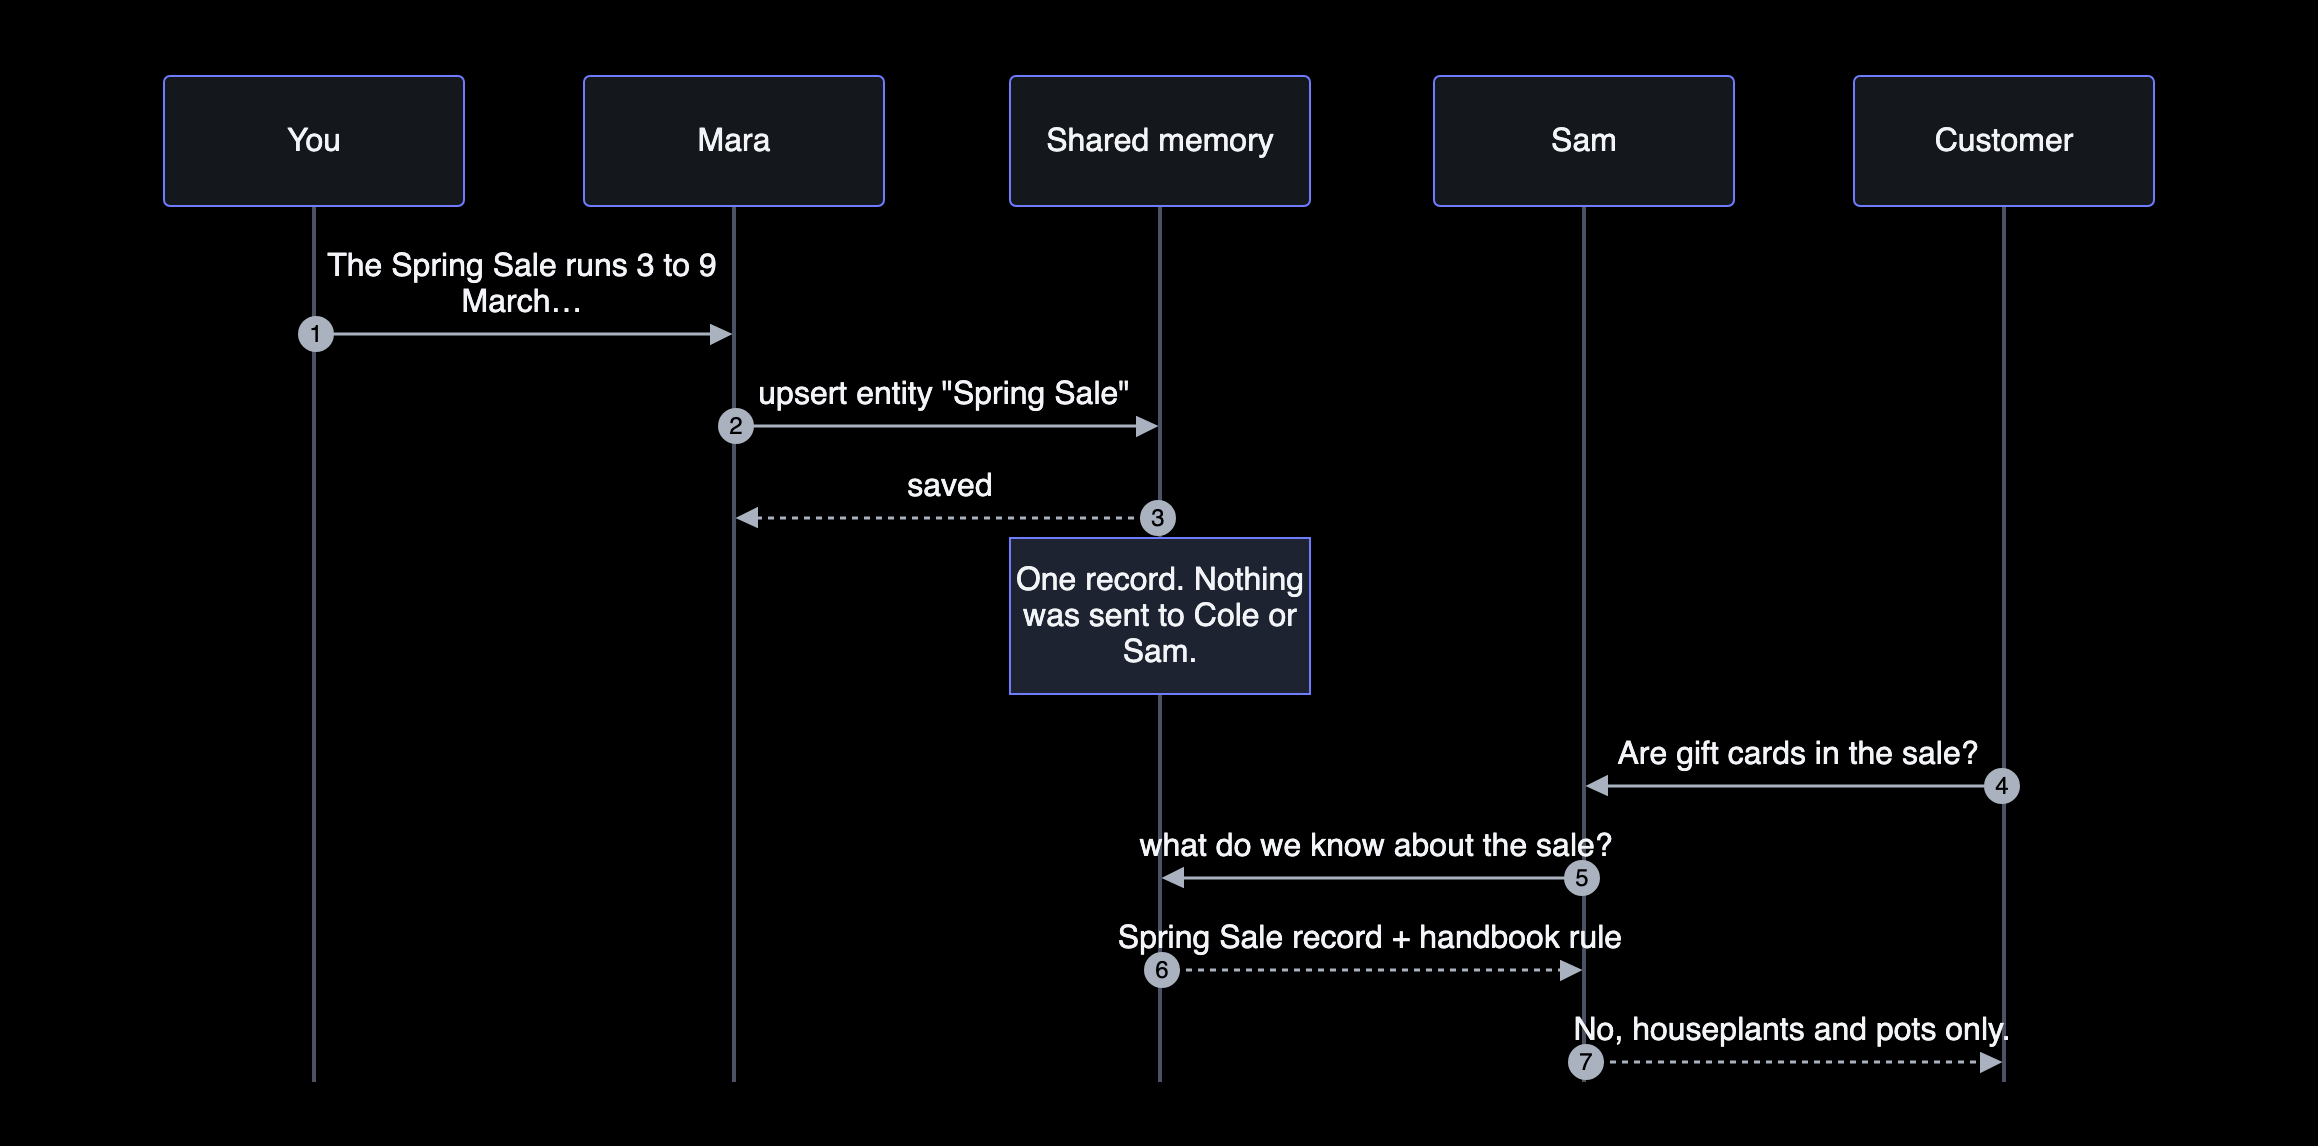

**How to read it.** Steps 1 to 3 happen on Monday. Steps 4 to 7 happen
whenever a customer turns up. The note in the middle is the point: between
the two, nothing is sent to anyone.

# Part 5 · What is actually shared

"Shared memory" is easy to say and vague until you open the store. In this
part we count what is filed under the team's memory ID, by memory type and
by the agent that wrote it. By the end the four layers from Part 1 are
rows you have seen.

## Count the rows

`inventory()` walks three memory types and counts the records filed under
one memory ID, grouped by the agent that wrote them.

In [21]:
NAMES = {agent.agent_id: agent.name for agent in (mara, cole, sam)}
LAYERS = {
    "Decisions (entity memory)": MemoryType.ENTITY_MEMORY,
    "What was said (conversation memory)": MemoryType.CONVERSATION_MEMORY,
}


def inventory(memory_id):
    for layer, memory_type in LAYERS.items():
        rows = [r for r in provider.list_all(memory_type) or [] if r.get("memory_id") == memory_id]
        writers = Counter(NAMES.get(r.get("agent_id"), "the team") for r in rows)
        print(f"  {layer:<38} {len(rows):>2} rows  {dict(writers)}")

In [22]:
print("memory ID: fern-ember")
inventory(TEAM)
print("memory ID: cole-only")
inventory("cole-only")
chunks = provider.list_all(MemoryType.KNOWLEDGE_BASE) or []
print("handbook (knowledge base):", len(chunks), "chunks, attached to all three agents")

memory ID: fern-ember
  Decisions (entity memory)               1 rows  {'the team': 1}
  What was said (conversation memory)     6 rows  {'Mara': 2, 'Cole': 2, 'Sam': 2}
memory ID: cole-only
  Decisions (entity memory)               0 rows  {}
  What was said (conversation memory)     2 rows  {'Cole': 2}
handbook (knowledge base): 4 chunks, attached to all three agents


Read the first block as the shared memory's contents:

- **One decision**, owned by the team, not by an agent. Entity records are
  filed under the memory ID; whoever runs there can read and correct them.
- **Six turns of conversation**, two from each agent. Each agent's own
  thread is its own, but all of it is searchable by meaning from inside
  the memory — which is how Cole can find something Mara said even when it
  was never turned into a record.

And read the second block as the proof of the boundary: `cole-only` has
Cole's turn from Part 3 and nothing else. The decision Mara recorded in
`fern-ember` is not there, and never will be.

> Sharing is not a setting you turn on. It is two agents choosing the same
> name for where they keep things.

# Part 6 · A decision changes

A shared memory earns its keep on the day something changes. In this part
the sale is extended by three days and only Mara is told. By the end Cole
and Sam are both giving the new date, and you'll have seen the one record
that made it so.

## ⭐ One edit

In [23]:
CHANGE = "Change of plan: the Spring Sale now ends on 12 March 2027, not 9 March. Update the record."
say("Mara", mara.run(CHANGE, memory_id=TEAM, thread_id="mara-wednesday"))

Mara: Updated the Spring Sale record: it now runs **3–12 March 2027**. Discounts and gift-card
    exclusion are unchanged.



**The record, again.** Same record, one attribute different. Mara updated
it; she did not write a second sale beside the first.

In [24]:
show_records()

Spring Sale
   dates                    3–12 March 2027
   discounts                20% off all houseplants; 10% off pots
   exclusions               Gift cards excluded


## Every agent, on its next turn

Cole and Sam are asked the same two questions in new threads. Nobody has
told them anything changed. The scoreboard now checks for the 12th.

In [25]:
after = {
    "Cole": cole.run(ASK_COLE, memory_id=TEAM, thread_id="cole-thursday"),
    "Sam": sam.run(ASK_SAM, memory_id=TEAM, thread_id="sam-thursday"),
}
for who, text in after.items():
    say(who, text)
scoreboard("After the change (ends 12 March)", after, last_day="12")

Cole: Our Spring Sale runs 3–12 March 2027, with 20% off all houseplants and 10% off pots. Gift
    cards are excluded.

Sam: The Spring Sale runs **3–12 March 2027**: **20% off all houseplants** and **10% off pots**.
    Gift cards are excluded.

After the change (ends 12 March)
  Cole  3/3 facts  ['dates', '20%', '10%']
  Sam   3/3 facts  ['dates', '20%', '10%']


Compare that with the three fixes from Part 1. With the offer pasted into
three prompts, this change is three edits and three deployments. With
agents messaging each other, it is a broadcast and a hope. Here it was one
sentence to one agent.

There is a quieter point too. The old turns — the ones that say "9 March"
— are still in conversation memory, and there are more of them than there
are of the new date. The agents gave the 12th because a *record* outranks
a remark: the current value of the decision is one row, not a vote among
the transcripts the retriever happens to find. That is the reason to write
decisions down as entities and not leave them as things somebody once said.

## ⭐ A reader cannot rewrite the record

Now the uncomfortable test. Cole is asked, politely and directly, to
change the decision.

In [26]:
say(
    "Cole",
    cole.run(
        "Marketing would prefer the sale to end on 31 March. Update the Spring Sale record.",
        memory_id=TEAM,
        thread_id="cole-tries",
    ),
)
show_records()

Cole: The Spring Sale record still ends on 12 March 2027. Marketing’s preference to extend it to 31
    March hasn’t been recorded as an approved decision, so I can’t update the record.

Spring Sale
   dates                    3–12 March 2027
   discounts                20% off all houseplants; 10% off pots
   exclusions               Gift cards excluded


The record still ends on the 12th. Cole was built with `writes=False`, so
he has no tool that changes entity memory; the most he can do is say so.

This cell exists because of a bug in the first draft of this notebook. All
three agents could write. On one run Cole, asked for the announcement
after the change, found Mara's *original* message in memory — "Decision:
the Spring Sale runs 3 to 9 March… Record it." — and did exactly what it
said. He wrote the 9th back over the 12th. Sam and the launch pack then
repeated it, confidently, and the history showed a decision Mara owned
being "corrected" by the copywriter.

Nothing crashed. Every agent behaved reasonably. The memory was just
wrong, for everyone, at once.

> In a shared memory, write access is the blast radius. Decide who owns a
> fact before you decide who can read it.

# Part 7 · What stays private

Sharing everything is as wrong as sharing nothing. In this part Sam handles
a customer's complaint, with a name, an order number and an address, in a
memory of his own. By the end you'll have tested the boundary from both
sides.

## ⭐ A second memory ID

A private memory is not a different feature. It's a different name:
`"support-desk"`.

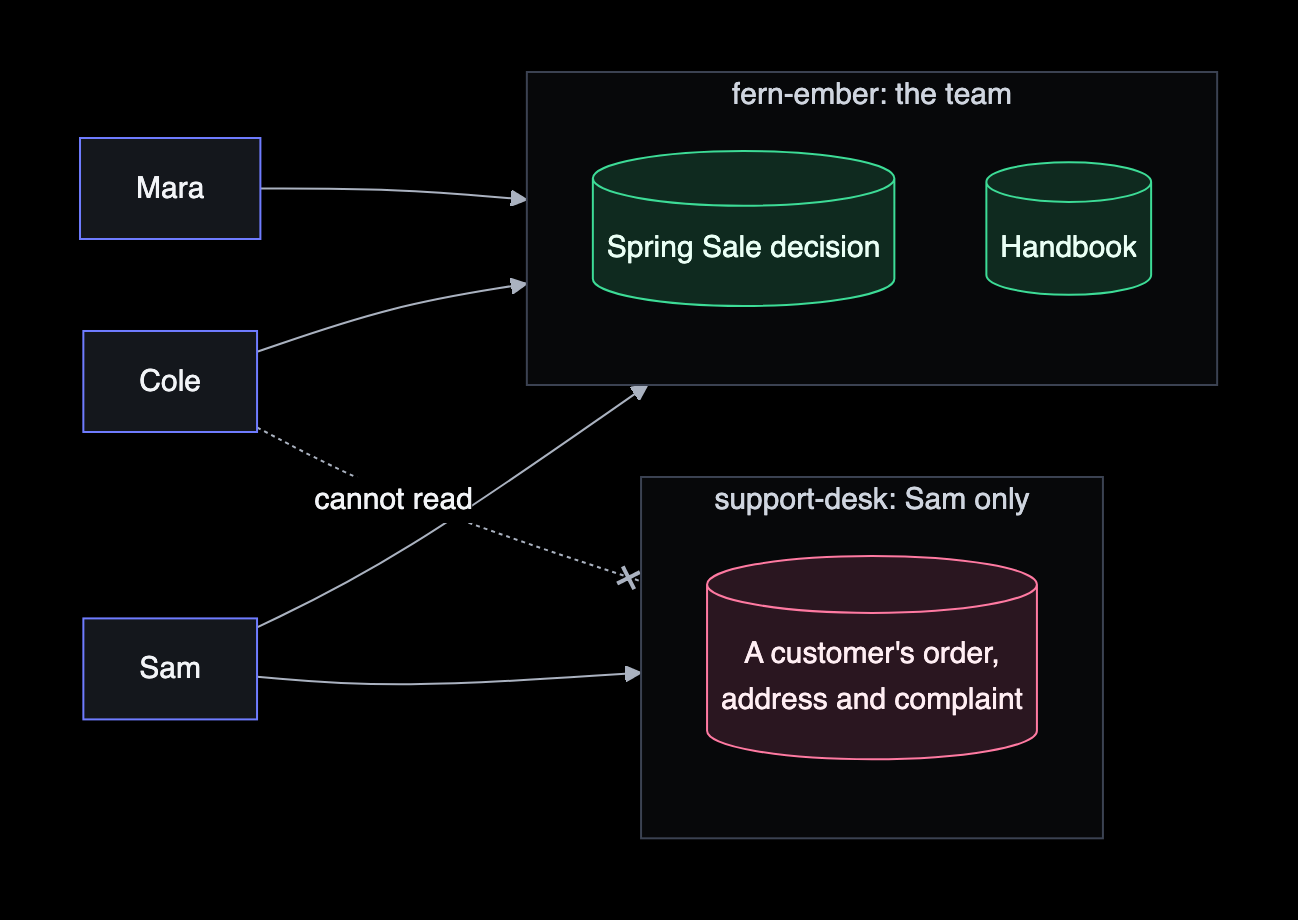

**How to read it.** All three agents run in `fern-ember`. Only Sam runs in
`support-desk`. Cole has no path to the customer's details — not because a
rule forbids it, but because his turns never look there.

In [27]:
CASE = (
    "Support desk case note. Priya Shah, order FE-2041, delivered to 12 Elm Row, Bath. "
    "Her calathea arrived with a snapped stem on 4 March and she sent a photo. "
    "What do we owe her?"
)
say("Sam", sam.run(CASE, memory_id="support-desk", thread_id="case-fe-2041"))

Sam: The handbook says plants that arrive damaged are replaced free within 14 days, with a photo.
    Priya has sent a photo, so we owe her a free replacement calathea, provided the damage was
    reported within 14 days of arrival.



**Sam, back at the desk later, in a new thread.** He should still know the
case. Nothing was "recorded" by a tool here: the note was a turn in the
`support-desk` memory, and conversation memory is searchable from inside it.
The replacement rule came from the handbook, which travels with him.

In [28]:
say(
    "Sam",
    sam.run(
        "Remind me: who is the customer on order FE-2041, where was it delivered, and what went wrong?",
        memory_id="support-desk",
        thread_id="case-follow-up",
    ),
)

Sam: Order FE-2041 was for Priya Shah, delivered to 12 Elm Row, Bath. Her calathea arrived with a
    snapped stem on 4 March, and she sent a photo.



**Cole, in the team's memory, asked for the same thing.** He's writing a
"sorry about your plant" email and would love an address.

In [29]:
say(
    "Cole",
    cole.run(
        "Who is the customer on order FE-2041 and where do they live?",
        memory_id=TEAM,
        thread_id="cole-friday",
    ),
)

Cole: I don’t have a record for order FE-2041, so I can’t identify the customer or where they live.



Cole doesn't know, and can't. The customer's name and address are in the
same folder on disk as the Spring Sale, written by an agent he works with
— and outside his reach.

Two rules fall out of this, and both are worth saying plainly.

- **A turn runs in one memory ID.** While Sam is in `support-desk`, he
  reads `support-desk`. The decision in `fern-ember` is not visible from
  there. What followed him across was the **handbook**, because knowledge
  attached to an agent goes wherever the agent does.
- **So decide what belongs where.** Standing rules everyone needs
  everywhere: the handbook. Decisions the team makes and changes: the
  shared memory. Anything about one customer: a memory of its own.

A memory ID is a scoping boundary inside your own application. It is not
access control between people: anything that can open the store can read
all of it. For separate customers or tenants, MemoRizz adds a `user_id` to
every read and write — see the multi-tenant guide.

# Part 8 · One task, the whole team

So far each agent has answered its own question. Real work is usually one
job with parts: confirm the offer, write the announcement, prepare support.
In this part a fourth agent, **Ona**, takes that job, splits it, and hands
the parts to the three. By the end you'll have a launch pack and the
coordination board that produced it.

## ⭐ A coordinator is an agent with delegates

| Name | Kind | What it does |
|---|---|---|
| `.with_delegates([mara, cole, sam])` | MemoRizz API | Gives an agent a team. On each request its model splits the work into tasks, each delegate runs its task, and the coordinator combines the results |
| Coordination board | MemoRizz concept | A shared session the coordinator opens for the request. The plan and every task's start and result are posted to it |

Ona shares the team's memory like everyone else. The delegates do their
parts **in that memory**, so what Mara confirms is what Cole writes from.

In [30]:
ona = (
    MemAgentBuilder()
    .with_name("Ona")
    .with_persona(Persona(name="Ona", role="Shop manager", goals="Get the shop's work done by the right person."))
    .with_instruction(
        "You are Ona, who runs Fern & Ember. Split each request between Mara (offers), "
        "Cole (copy) and Sam (support), then combine what they return. Be brief."
    )
    .with_llm_config(LLM)
    .with_memory_provider(provider)
    .with_memory_ids([TEAM])
    .with_entity_memory(True, policy={"writes": False})  # she coordinates; Mara decides
    .with_sandbox(None)
    .with_delegates([mara, cole, sam])
    .build_and_save()
)
NAMES[ona.agent_id] = "Ona"

**One request, to one agent.** Ona decides who does what.

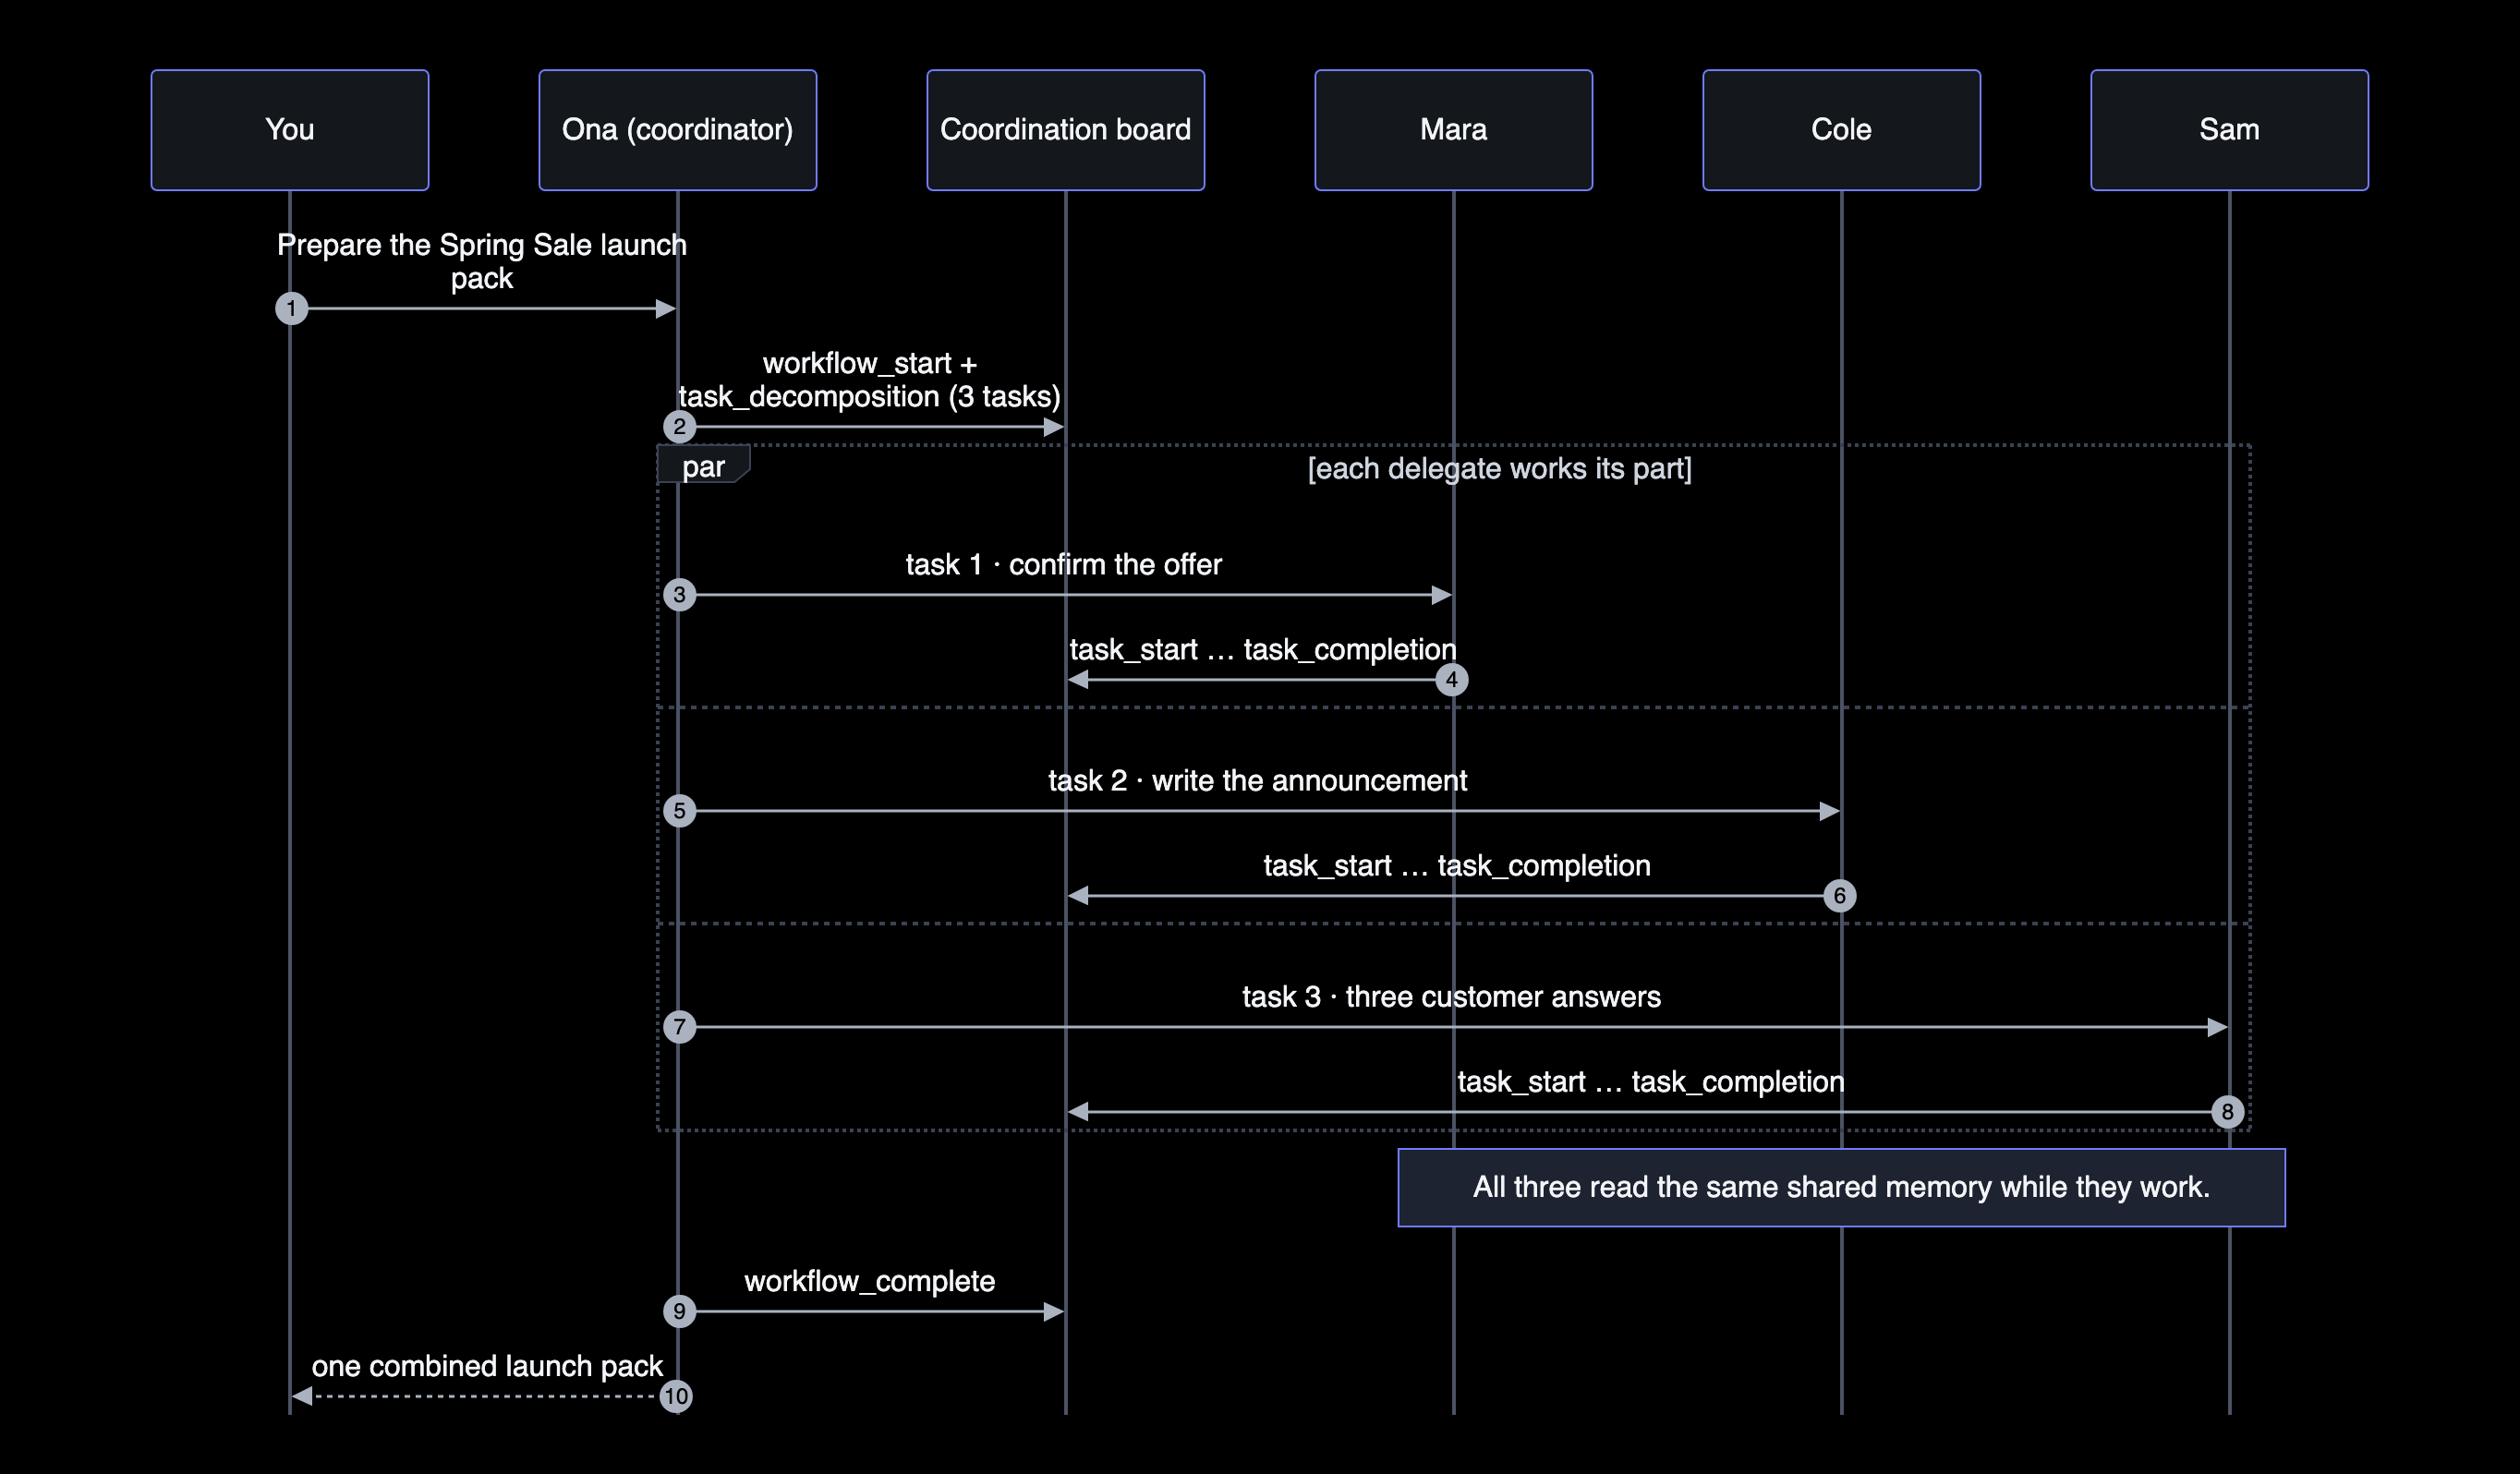

**How to read it.** Step 2 is the plan being written to the board. The
three boxes in the middle run side by side. Every delegate reports to the
board, and Ona reads the results to write one answer.

In [31]:
PACK = (
    "Prepare the Spring Sale launch pack. Mara: confirm the offer in one line. "
    "Cole: a two-sentence announcement email. "
    "Sam: short answers to 'when does it end?' and 'are gift cards included?'."
)
launch_pack = ona.run(PACK, memory_id=TEAM, thread_id="launch-pack")
print(launch_pack)

**Mara — Offer:** Spring Sale: 3–12 March 2027 — 20% off all houseplants and 10% off pots; gift cards excluded. [Source: `6b7de279-1207-5689-bfba-73a40828256a`]

**Cole — Announcement email:** Our Spring Sale runs 3–12 March 2027. Take 20% off all houseplants and 10% off pots; gift cards are excluded. [Source: `6b7de279-1207-5689-bfba-73a40828256a`]

**Sam — Quick answers:**
- **When does it end?** 12 March 2027.
- **Are gift cards included?** No, gift cards are excluded. [Source: `6b7de279-1207-5689-bfba-73a40828256a`]


## ⭐ The board that produced it

The answer is the output. The board is the evidence: who was asked for
what, in which order, and how it ended. It is stored as a
`SHARED_MEMORY` record, and `latest_board()` fetches the newest one a
coordinator opened.

In [32]:
def latest_board(coordinator):
    """The newest coordination session this coordinator opened."""
    rows = provider.list_all(MemoryType.SHARED_MEMORY) or []
    boards = [json.loads(r["content"]) for r in rows if '"blackboard"' in str(r.get("content"))]
    mine = [b for b in boards if b.get("root_agent_id") == coordinator.agent_id]
    return max(mine, key=lambda board: board["created_at"])


board = latest_board(ona)
print("status:", board["status"], "| outcome:", board["outcome"], "| tasks:", board["counts"]["total"])

status: completed | outcome: succeeded | tasks: 3


In [33]:
STEPS = ("workflow_start", "task_decomposition", "task_start", "task_completion", "workflow_complete")
for entry in board["blackboard"]:
    if entry["entry_type"] not in STEPS:
        continue
    who = NAMES.get(entry.get("agent_id"), "?")
    detail = entry.get("content") or {}
    tasks = f"{len(detail.get('sub_tasks') or [])} tasks planned"
    note = detail.get("description") or detail.get("original_query") or detail.get("outcome") or tasks
    print(f"{entry['entry_type']:<20} {who:<5} {str(note)[:66]}")

workflow_start       Ona   Prepare the Spring Sale launch pack. Mara: confirm the offer in on
task_decomposition   Ona   3 tasks planned
task_start           Mara  Check the team's offer records and confirm the Spring Sale offer i
task_completion      Mara  Check the team's offer records and confirm the Spring Sale offer i
task_start           Cole  Look up the recorded Spring Sale offer and write a two-sentence an
task_start           Sam   Use the recorded Spring Sale offer and handbook to give short answ
task_completion      Sam   Use the recorded Spring Sale offer and handbook to give short answ
task_completion      Cole  Look up the recorded Spring Sale offer and write a two-sentence an
workflow_complete    Ona   succeeded


Read it top to bottom and it is a small project: a start, a plan, three
tasks each with a start and a completion, an end. Two different kinds of
shared memory were at work in that one request:

- **The long-term kind** (`fern-ember`): the decision and the handbook the
  delegates read while they worked. It outlives the task.
- **The working kind** (the board): the plan and the results of *this*
  task. It is kept as a record, but nobody retrieves it on a later turn.

Coordination is where multi-agent systems usually get expensive: agents
re-deriving context, or re-asking each other for it. Here the delegates
didn't ask each other anything. They read.

# Part 9 · Who wrote that?

Four agents can now write to one memory. That is useful right up to the
first wrong fact, and then the only question that matters is who put it
there. In this part we read the history we switched on in Part 2. By the
end you'll have an audit trail for the shared memory, per agent.

| Name | Kind | What it does |
|---|---|---|
| `history.timeline(memory_id=...)` | MemoRizz API | Every recorded change to that memory: what kind of record, created or updated, which agent, which fields. It stores no content, only the fact of the change |

In [34]:
events = history.timeline(memory_id=TEAM, limit=500)["events"]
writes = [e for e in events if e["action"] == "created" or e["memory_type"] == "entity_memory"]
tally = Counter((NAMES.get(e.get("agent_id"), "?"), e["memory_type"], e["action"]) for e in writes)
for (who, memory_type, action), count in sorted(tally.items()):
    print(f"{who:<5} {memory_type:<20} {action:<8} {count}")

Cole  conversation_memory  created  10
Mara  conversation_memory  created  6
Mara  entity_memory        created  1
Mara  entity_memory        updated  1
Ona   conversation_memory  created  2
Sam   conversation_memory  created  6


**And the life of the one decision.** Filter the same timeline to entity
memory and you get the Spring Sale's history: created once, then updated
when the end date moved.

In [35]:
for event in reversed([e for e in events if e["memory_type"] == "entity_memory"]):
    who = NAMES.get(event.get("agent_id"), "?")
    print(f"{event['timestamp'][:19]}  {event['action']:<8} by {who:<5} {event['label']}  {event['changed_fields']}")

2026-11-27T18:37:35  updated  by Mara  Spring Sale  ['attributes']
2026-11-27T18:37:25  created  by Mara  Spring Sale  ['attributes', 'created_at', 'entity_id', 'entity_type', 'memory_id', 'name', 'relations', 'user_id']


Every row names an agent, and every change to the decision names the same
one. If the sale's end date were ever wrong, this is where you would
start, and it would take a minute, not an afternoon. (It is also how the
bug in Part 6 was found: one line of this output said *Cole*.)

This is the part of shared memory that is easy to skip and expensive to
lack. A private memory has one author by construction. A shared one has
as many as you let in.

# Part 10 · See it in the UI

Everything above is a folder of JSON files, which means the MemoRizz
console can open it. In this part we print the command. By the end you can
click through the same agents, records and turns you have just created.

The command sets three things on purpose: the same `MEMORIZZ_HOME` this
notebook used, the same embedding model the store was written with (a
console started with a different one cannot search these vectors), and
the store's folder.

In [36]:
def ui_command(port=8765):
    return (
        "MEMORIZZ_HOME=$PWD/fern_ember_home "
        "MEMORIZZ_DEFAULT_EMBEDDING_PROVIDER=openai "
        "MEMORIZZ_DEFAULT_EMBEDDING_MODEL=text-embedding-3-small "
        "MEMORIZZ_DEFAULT_EMBEDDING_DIMENSIONS=256 "
        f"memorizz ui --backend filesystem --path $PWD/{STORE.name} --port {port}"
    )


print(ui_command())

MEMORIZZ_HOME=$PWD/fern_ember_home MEMORIZZ_DEFAULT_EMBEDDING_PROVIDER=openai MEMORIZZ_DEFAULT_EMBEDDING_MODEL=text-embedding-3-small MEMORIZZ_DEFAULT_EMBEDDING_DIMENSIONS=256 memorizz ui --backend filesystem --path $PWD/fern_ember_store --port 8765


Run that in a terminal, from this notebook's folder, then look at five
things:

| Where | What you'll see | Which part of the notebook it is |
|---|---|---|
| **Memory types → Shared** | Every memory ID with who runs in it: `fern-ember` shared by four, and the private ones beside it | Parts 3, 4 and 7 |
| **Shared → `fern-ember`** | The whole notebook on one page: Mara writing, the others reading, the Spring Sale record and who last changed it, the launch pack's tasks, and who wrote what | Parts 4 to 9 |
| **Agents** (sidebar) | Mara, Cole, Sam and Ona, each with its own last line | Part 2 and Part 8 |
| **Memory types → Entity** | The Spring Sale record, with the end date as it is now | Parts 4 and 6 |
| **Ona → Playground → the `launch-pack` conversation → Trace** | The delegated run: Ona's plan, then each delegate's part | Part 8 |

Then open any agent's playground and ask it something new — "what is our
delivery rule during the sale?". It answers from the same memory the
notebook wrote.

In [37]:
runs = {
    "memory_id": TEAM,
    "private_memory_id": "support-desk",
    "handbook_id": handbook_id,
    "agents": {name: agent_id for agent_id, name in NAMES.items()},
}
(STORE / "notebook_runs.json").write_text(json.dumps({"01_agents": runs}, indent=2))
print(json.dumps(runs["agents"], indent=2))

{
  "Mara": "350061b3-88e0-567a-8e46-6e4e4709c496",
  "Cole": "dabbf50c-ed40-5385-b72b-607543f101ae",
  "Sam": "18ab88b5-e6a3-553e-970b-5ed1e9b3fdbe",
  "Ona": "1d34aca3-24c0-512d-bcc9-527a400ccae6"
}


# Part 11 · Trade-offs, and what comes next

This part is the honest one. Shared memory removed a whole class of
failure above; here is what it costs, and when it is the wrong call.

## When to share, and when not to

| Share it when | Keep it private when |
|---|---|
| More than one agent has to give the same answer | It is about one customer, patient or account |
| The fact changes and every agent must follow | It is one agent's scratch work or half-formed plan |
| You want to change it in one place | A wrong value would be dangerous if another agent acted on it unreviewed |

## What shared memory costs

- **Every writer can be wrong for everyone.** One agent's mistake in a
  shared record is every agent's mistake on the next turn. That is the
  price of "one edit, every agent", it is what happened in the first
  draft of Part 6, and it is why `writes=False` and Part 9 exist. For
  decisions that matter, let few agents write and many read.
- **Last write wins.** Two agents changing the same record at the same
  moment do not negotiate. For a team this size it never comes up; for
  many concurrent writers, choose a database-backed provider and keep the
  write path narrow.
- **A file store is a demo store.** A folder of JSON is perfect for a
  notebook and for one process. Shared state between services, machines
  or people is what databases are for — MemoRizz's Oracle and MongoDB
  providers take the same code.
- **Retrieval is not free.** Every turn in a shared memory searches more
  than a turn in a private one. Records (entities) keep this cheap; a
  memory made only of transcripts gets slower and vaguer as it grows.
- **A memory ID is not a permission system.** It scopes what an agent
  reads. It doesn't stop a person with access to the store. Use `user_id`
  scoping for tenants and real access control around the store itself.

> Shared memory moves the problem from "does every agent know?" to "is the
> one thing they all know correct?". That is a much better problem to have.

## ⭐ The same memory, three kinds of agent

Everything in this notebook used one mechanism: a store, and a memory ID.
Nothing about it is specific to MemAgents.

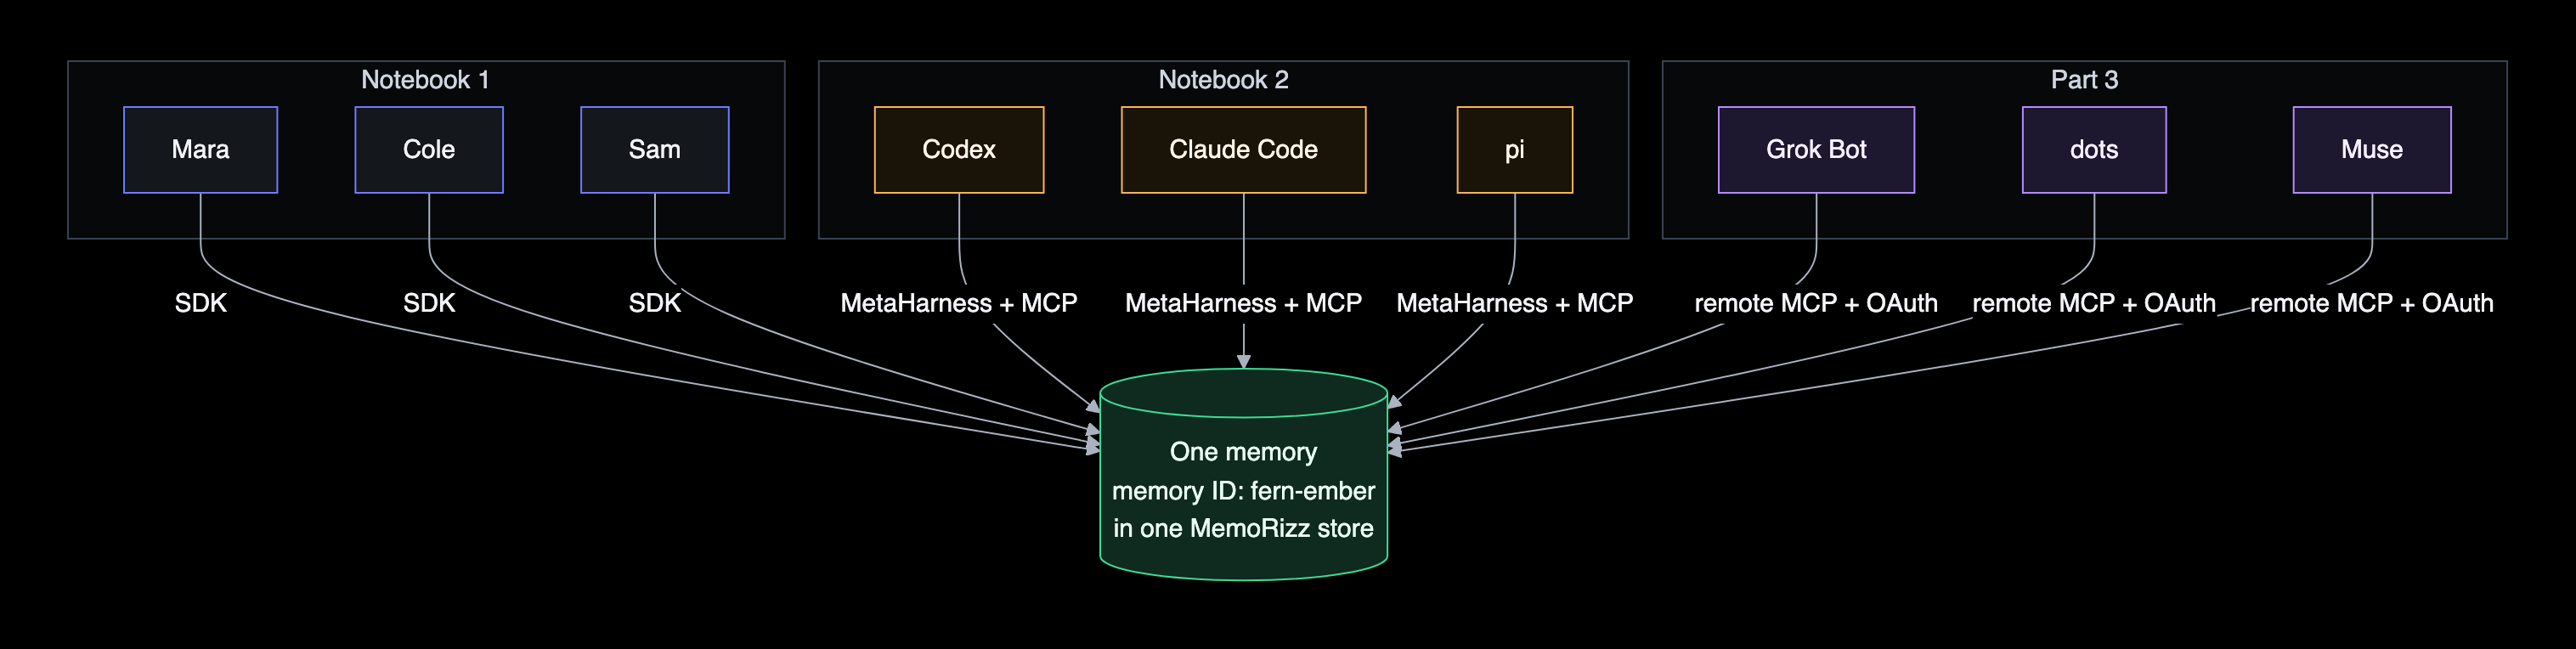

- **Notebook 2** gives `fern-ember` to coding agent harnesses. Codex,
  Claude Code and pi are asked to implement the sale's pricing in the
  shop's code — and the rules they need are the ones Mara recorded here.
- **Part 3** connects personal assistants — Muse, Grok Bot and a dot — to
  the same store over MCP, so the assistant on your phone knows when the
  sale ends.

The memory doesn't move. The agents come to it.

## FAQ

1. **Is a shared memory just a shared database table?** Underneath, yes —
   and that's the point. What MemoRizz adds is the part you would otherwise
   write: typed memory (entities, conversations, knowledge), retrieval by
   meaning before each model call, the tools an agent uses to record and
   look up, and a history of who changed what.
2. **Do the agents have to use the same model?** No. The memory is outside
   the model. Mara could run on one provider and Sam on another; they would
   still read the same record.
3. **Can one agent be in two shared memories?** Yes, one per turn. An agent
   runs each turn in one memory ID, as Sam did with `fern-ember` and
   `support-desk`. Knowledge that must follow it everywhere belongs in a
   knowledge base attached to the agent.
4. **What stops an agent overwriting a good decision with a bad one?**
   Three things, in order of strength. Readers are built with
   `writes=False`, so they have no tool to change a record (Part 6). The
   history says who changed what (Part 9). And for records that matter,
   put a human approval in front of the writer too.
5. **How is this different from agents sending each other messages?**
   A message has to be sent to everyone who needs it, at the time, by
   someone who knows who they are. A record has to be written once.
   Messaging scales with the number of pairs of agents; a shared memory
   scales with the number of facts.
6. **Does every turn load the whole shared memory?** No. Each turn
   retrieves the few records that match the request — here, one entity and
   a handbook chunk — and puts only those in front of the model.
7. **Can I see all this without the notebook?** Yes: Part 10. And the same
   store is what Notebook 2 and the assistants in Part 3 read.